<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab3SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np
from google.colab import drive

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
drive.mount("/content/drive")
ARTIFACTS = Path("/content/drive/MyDrive/cv_lab3_artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


Mounted at /content/drive
{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
from torchvision.datasets import OxfordIIITPet
from torchvision import transforms
from transformers import SamModel, SamProcessor
import numpy as np

# загрузка SAM
model_name = "facebook/sam-vit-base"
processor = SamProcessor.from_pretrained(model_name)
model = SamModel.from_pretrained(model_name).to(DEVICE)
model.eval()

# трансформации для Oxford-IIIT Pet
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

target_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor(),
])

# загрузка датасета
full_ds = OxfordIIITPet(
    root=str(DATA_ROOT / "oxford-iiit-pet"),
    split="test",
    target_types="segmentation",
    download=True,
    transform=transform,
    target_transform=target_transform,
)

# разделение на trainval и test
n_total = len(full_ds)
indices = list(range(n_total))
random.shuffle(indices)

if FAST_DEV_RUN:
    eval_indices = indices[:5]
    train_indices = indices[5:10]
else:
    eval_indices = indices[:50]
    train_indices = indices[50:250]

eval_ds = torch.utils.data.Subset(full_ds, eval_indices)

manifest = {
    "model_name": model_name,
    "eval_indices": eval_indices,
    "train_indices": train_indices,
    "num_eval": len(eval_indices),
    "fast_dev_run": FAST_DEV_RUN,
    "image_size": 256,
    "dataset": "oxford-iiit-pet",
}
with open(ARTIFACTS / "dataset_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print(f"Загружено {len(eval_indices)} eval изображений, {len(train_indices)} train изображений")


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Загружено 50 eval изображений, 200 train изображений


я загрузил предобученную модель SAM, которая умеет выделять объекты на изображении по промтам(точка, прямоугольник), ей на вход подается изображение, она его ресайзит до размера 1024х1024, прогоняет через image encoder, который превращает картинку в эмбеддинг(карта признаков), дальше модель ждет промт, обрабатывает его через prompt encoder и потом mask decoder объединяет оба эмбединга и выдает финальную маску

### Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
def iou(pred_mask, gt_mask):
    pred = (np.asarray(pred_mask) > 0.5).astype(bool)

    gt_arr = np.asarray(gt_mask)
    if gt_arr.dtype == bool:
        gt = gt_arr
    else:
        # Oxford-IIIT Pet 1 = питомец, 2 = фон, 3 = контур
        # если в массиве есть значения > 1 — считаем через = 1
        if set(np.unique(gt_arr).tolist()) - {0, 1}:
            gt = (gt_arr == 1)
        else:
            gt = (gt_arr > 0.5).astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0
    return float(intersection / union)


def box_from_mask(mask):
    mask = np.asarray(mask)
    # если есть значения > 1 берем =1
    if mask.dtype != bool and set(np.unique(mask).tolist()) - {0, 1}:
        mask = (mask == 1)
    mask = mask.astype(bool)

    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)

    if not rows.any() or not cols.any():
        return [0, 0, 0, 0]

    y_min, y_max = np.where(rows)[0][[0, -1]]
    x_min, x_max = np.where(cols)[0][[0, -1]]

    return [int(x_min), int(y_min), int(x_max), int(y_max)]


def point_from_mask(mask):
    mask = np.asarray(mask)
    if mask.dtype != bool and set(np.unique(mask).tolist()) - {0, 1}:
        mask = (mask == 1)
    mask = mask.astype(bool)

    ys, xs = np.where(mask)
    if len(ys) == 0:
        return (0, 0)
    return (int(np.median(xs)), int(np.median(ys)))


# тест на синтетической маске
dummy_mask = np.zeros((10, 10))
dummy_mask[3:8, 2:7] = 1
print(f"box_from_mask: {box_from_mask(dummy_mask)}")
print(f"point_from_mask: {point_from_mask(dummy_mask)}")
print(f"IoU identical: {iou(dummy_mask, dummy_mask)}")

# сырая GT с классами 1/2/3
raw_mask = np.full((10, 10), 2, dtype=np.int64) #фон
raw_mask[3:8, 2:7] = 1 # питомец
print(f"\nНа сырой GT:")
print(f"  box_from_mask: {box_from_mask(raw_mask)}")
print(f"  point_from_mask: {point_from_mask(raw_mask)}")

box_from_mask: [2, 3, 6, 7]
point_from_mask: (4, 5)
IoU identical: 1.0

На сырой GT:
  box_from_mask: [2, 3, 6, 7]
  point_from_mask: (4, 5)


я написал измеритель качества (IoU) и два генератора промптов (point и box),чтобы потом подавать SAM подсказки и оценивать, насколько хорошо он сегментирует, протестировал на примере взял маску 10х10 и внутри нарисовал квадрат 5х5(х:2-6, y:3-7), получилось, что функция находит рамку вокруг квадрата box_from_mask: [2, 3, 6, 7] и другая функция находит медиану тобмшь точку в центре квадрата point_from_mask: (4, 5) и маска совпала сама с собой значит все хорошо

### Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
def predict_sam(image, processor, model, point=None, box=None, device=DEVICE):
    from PIL import Image

    if isinstance(image, torch.Tensor):
        # конвертация из тензора (C,H,W) в PIL
        image_np = image.permute(1, 2, 0).cpu().numpy()
        image_np = (image_np * 255).astype(np.uint8)
        image = Image.fromarray(image_np)

    orig_size = image.size

    if point is not None:
        input_points = [[[point[0], point[1]]]]
        input_labels = [[[1]]]
        inputs = processor(
            images=image,
            input_points=input_points,
            input_labels=input_labels,
            return_tensors="pt",
        ).to(device)
    elif box is not None:
        input_boxes = [[[box[0], box[1], box[2], box[3]]]]
        inputs = processor(
            images=image,
            input_boxes=input_boxes,
            return_tensors="pt",
        ).to(device)
    else:
        raise ValueError("Укажите point или box")

    with torch.no_grad():
        outputs = model(**inputs)

    masks = processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu(),
    )[0]

    scores = torch.sigmoid(outputs.iou_scores).cpu().numpy()[0, 0]

    # выбор маски с наивысшей оценкой IoU
    best_idx = np.argmax(scores)
    best_mask = masks[0, best_idx].numpy()
    best_score = scores[best_idx]

    return best_mask.astype(bool), float(best_score)


# тест на eval изображении
img_tensor, gt_mask = eval_ds[0]
gt_mask_np = gt_mask.numpy().squeeze()
gt_bin = (gt_mask_np == 1)

box = box_from_mask(gt_bin)
pt  = point_from_mask(gt_bin)

pred_point, score_point = predict_sam(img_tensor, processor, model, point=pt)
pred_box,   score_box   = predict_sam(img_tensor, processor, model, box=box)

print(f"Point IoU: {iou(pred_point, gt_bin):.3f}, SAM score: {score_point:.3f}")
print(f"Box IoU: {iou(pred_box, gt_bin):.3f}, SAM score: {score_box:.3f}")

Point IoU: 0.028, SAM score: 0.730
Box IoU:   0.831, SAM score: 0.730


тут научили SAM отвечать на промпты и проверили, что он делает это правильно,на тестовом изображении box дал IoU 0.83, point 0.03, что уже намекает, что box точнее, а точка дает перемнный успех в зависимости куда она попадет, при этом в обоих случаях модель уверена

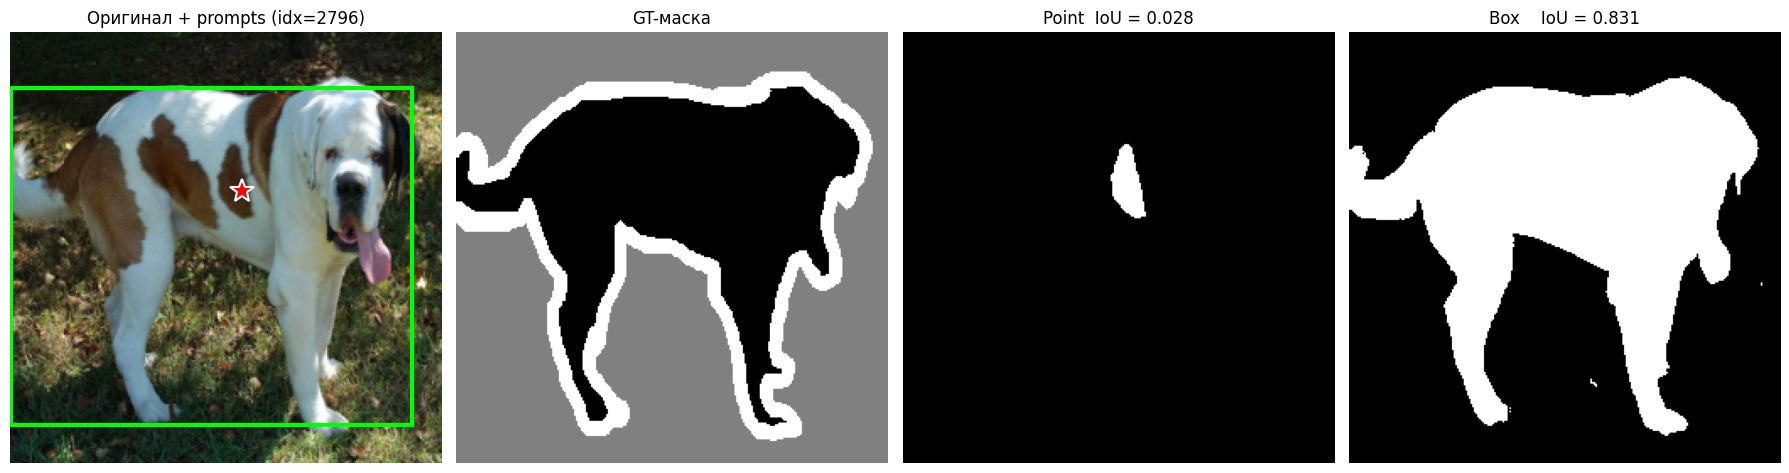

In [ ]:
import matplotlib.pyplot as plt

def show_sam_sanity(idx):
    img_t, gt_t = full_ds[idx]
    gt_np = gt_t.numpy().squeeze()
    img_np = img_t.permute(1, 2, 0).numpy()

    pt = point_from_mask(gt_np)
    bx = box_from_mask(gt_np)
    m_pt, s_pt = predict_sam(img_t, processor, model, point=pt)
    m_bx, s_bx = predict_sam(img_t, processor, model, box=bx)

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(img_np)
    axes[0].plot(pt[0], pt[1], "r*", ms=18, markeredgecolor="white", markeredgewidth=1.5)
    x0, y0, x1, y1 = bx
    axes[0].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0,
                                    fill=False, edgecolor="lime", linewidth=3))
    axes[0].set_title(f"Оригинал + prompts (idx={idx})")

    axes[1].imshow(gt_np, cmap="gray")
    axes[1].set_title("GT-маска")

    axes[2].imshow(m_pt, cmap="gray")
    axes[2].set_title(f"Point  IoU = {iou(m_pt, gt_np):.3f}")

    axes[3].imshow(m_bx, cmap="gray")
    axes[3].set_title(f"Box    IoU = {iou(m_bx, gt_np):.3f}")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_sam_sanity(eval_indices[0])

### Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from transformers import SamModel, SamProcessor

model_name = "Zigeng/SlimSAM-uniform-50"
processor = SamProcessor.from_pretrained(model_name)
model = SamModel.from_pretrained(model_name).to(DEVICE)
model.eval()

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

SamModel(
  (shared_image_embedding): SamPositionalEmbedding()
  (vision_encoder): SamVisionEncoder(
    (patch_embed): SamPatchEmbeddings(
      (projection): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    )
    (layers): ModuleList(
      (0-11): 12 x SamVisionLayer(
        (layer_norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): SamVisionSdpaAttention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (proj): Linear(in_features=384, out_features=384, bias=True)
        )
        (layer_norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): SamMLPBlock(
          (lin1): Linear(in_features=384, out_features=1536, bias=True)
          (lin2): Linear(in_features=1536, out_features=384, bias=True)
          (act): GELUActivation()
        )
      )
    )
    (neck): SamVisionNeck(
      (conv1): Conv2d(384, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (layer_norm1): SamLayerNorm((25

In [ ]:
from tqdm.auto import tqdm
import json

prompt_results = []

for idx in tqdm(eval_indices, desc="point vs box"):
    img_tensor, gt_mask = full_ds[idx]
    gt_mask_np = gt_mask.numpy().squeeze()

    # бинаризация питомец = True, фон и контур = False
    gt_bin = (gt_mask_np == 1)
    if gt_bin.sum() == 0:
        continue

    # промпты из бинарной маски
    box = box_from_mask(gt_bin)
    pt  = point_from_mask(gt_bin)

    # предсказания SAM
    pred_point, score_point = predict_sam(img_tensor, processor, model, point=pt)
    pred_box,   score_box   = predict_sam(img_tensor, processor, model, box=box)

    prompt_results.append({
        "index": idx,
        "point": {"coords": pt,  "iou": float(iou(pred_point, gt_bin)),
                  "sam_score": score_point, "area": int(pred_point.sum())},
        "box": {"coords": box, "iou": float(iou(pred_box, gt_bin)),
                  "sam_score": score_box, "area": int(pred_box.sum())},
        "gt_area": int(gt_bin.sum()),
    })

with open(ARTIFACTS / "prompt_results.json", "w") as f:
    json.dump(prompt_results, f, indent=2)

point_ious = [r["point"]["iou"] for r in prompt_results]
box_ious   = [r["box"]["iou"]   for r in prompt_results]

print(f"Point mean IoU: {np.mean(point_ious):.3f} (n={len(prompt_results)})")
print(f"Box mean IoU: {np.mean(box_ious):.3f}")

point vs box:   0%|          | 0/50 [00:00<?, ?it/s]

Point mean IoU: 0.635 (n=50)
Box mean IoU:   0.773


### Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import json
import torch
import numpy as np
import random
from pathlib import Path
from PIL import Image
from torchvision.datasets import OxfordIIITPet
from torchvision import transforms
from transformers import SamModel, SamProcessor

model_name = "Zigeng/SlimSAM-uniform-50"
processor = SamProcessor.from_pretrained(model_name)
model = SamModel.from_pretrained(model_name).to(DEVICE)
model.eval()

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])
target_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor(),
])

full_ds = OxfordIIITPet(
    root=str(DATA_ROOT / "oxford-iiit-pet"),
    split="trainval",
    target_types="segmentation",
    download=True,
    transform=transform,
    target_transform=target_transform,
)

manifest_path = ARTIFACTS / "dataset_manifest.json"
if manifest_path.exists():
    with open(manifest_path) as f:
        manifest = json.load(f)
    eval_indices = manifest["eval_indices"]
    train_indices = manifest["train_indices"]
    print(f"Индексы из manifest: eval={len(eval_indices)}, train={len(train_indices)}")
else:
    raise FileNotFoundError("dataset_manifest.json не найден!")


pr_path = ARTIFACTS / "prompt_results.json"
if pr_path.exists():
    with open(pr_path) as f:
        prompt_results = json.load(f)
    p_ious = [r["point"]["iou"] for r in prompt_results]
    b_ious = [r["box"]["iou"] for r in prompt_results]
    print(f"prompt_results: {len(prompt_results)} записей")
    print(f"Point mean IoU: {np.mean(p_ious):.3f}")
    print(f"Box mean IoU:   {np.mean(b_ious):.3f}")
else:
    raise FileNotFoundError("prompt_results.json не найден!")

def iou(pred_mask, gt_mask):
    pred = (np.asarray(pred_mask) > 0.5).astype(bool)
    gt_arr = np.asarray(gt_mask)
    if gt_arr.dtype == bool:
        gt = gt_arr
    else:
        if set(np.unique(gt_arr).tolist()) - {0, 1}:
            gt = (gt_arr == 1)
        else:
            gt = (gt_arr > 0.5).astype(bool)
    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    if union == 0: return 1.0 if intersection == 0 else 0.0
    return float(intersection / union)

def box_from_mask(mask):
    mask = np.asarray(mask)
    if mask.dtype != bool and set(np.unique(mask).tolist()) - {0, 1}:
        mask = (mask == 1)
    mask = mask.astype(bool)
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    if not rows.any() or not cols.any(): return [0, 0, 0, 0]
    y_min, y_max = np.where(rows)[0][[0, -1]]
    x_min, x_max = np.where(cols)[0][[0, -1]]
    return [int(x_min), int(y_min), int(x_max), int(y_max)]

def point_from_mask(mask):
    mask = np.asarray(mask)
    if mask.dtype != bool and set(np.unique(mask).tolist()) - {0, 1}:
        mask = (mask == 1)
    mask = mask.astype(bool)
    ys, xs = np.where(mask)
    if len(ys) == 0: return (0, 0)
    return (int(np.median(xs)), int(np.median(ys)))

def predict_sam(image, processor, model, point=None, box=None, device=DEVICE):
    if isinstance(image, torch.Tensor):
        image_np = image.permute(1, 2, 0).cpu().numpy()
        image_np = (image_np * 255).astype(np.uint8)
        image = Image.fromarray(image_np)
    if point is not None:
        inputs = processor(images=image, input_points=[[[int(point[0]), int(point[1])]]], input_labels=[[[1]]], return_tensors="pt").to(device)
    elif box is not None:
        inputs = processor(images=image, input_boxes=[[[float(box[0]), float(box[1]), float(box[2]), float(box[3])]]], return_tensors="pt").to(device)
    else:
        raise ValueError("Укажите point или box")
    with torch.no_grad():
        outputs = model(**inputs)
    masks = processor.image_processor.post_process_masks(outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
    scores = torch.sigmoid(outputs.iou_scores).cpu().numpy()[0, 0]
    best_idx = int(np.argmax(scores))
    return masks[0, best_idx].numpy().astype(bool), float(scores[best_idx])

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/365 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  112MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

100%|██████████| 792M/792M [00:22<00:00, 35.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 14.3MB/s]


Индексы из manifest: eval=50, train=200
prompt_results: 50 записей
Point mean IoU: 0.635
Box mean IoU:   0.773


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
from tqdm.auto import tqdm
import numpy as np
import time

# датасет
class PetBinarySeg(Dataset):
    def __init__(self, base_ds, indices):
        self.base = base_ds
        self.indices = list(indices)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, mask = self.base[self.indices[i]]
        m = mask.numpy().squeeze()
        return img, torch.from_numpy((m == 1).astype(np.float32)).unsqueeze(0)


train_ds = PetBinarySeg(full_ds, train_indices)
val_ds   = PetBinarySeg(full_ds, eval_indices)
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=0)


# модель с 1 выходным классом
lraspp = lraspp_mobilenet_v3_large(weights="DEFAULT")

#замена только выходных сверток (in_channels не меняется)
lraspp.classifier.low_classifier  = nn.Conv2d(40,  1, 1)
lraspp.classifier.high_classifier = nn.Conv2d(128, 1, 1)

lraspp = lraspp.to(DEVICE)

with torch.no_grad():
    dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
    out = lraspp(dummy)["out"]
    assert out.shape == (1, 1, 256, 256), f"Неверная форма выхода: {out.shape}"


# обучение
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(lraspp.parameters(), lr=1e-4)

num_epochs = 5 if FAST_DEV_RUN else 10
best_val_iou = -1.0
best_state = None
t0 = time.time()

for epoch in range(num_epochs):
    lraspp.train()
    total_loss = 0
    for imgs, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [train]", leave=False):
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        outputs = lraspp(imgs)["out"]
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    lraspp.eval()
    val_ious = []
    with torch.no_grad():
        for imgs, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [val]", leave=False):
            imgs = imgs.to(DEVICE)
            outputs = lraspp(imgs)["out"]
            preds = (torch.sigmoid(outputs) > 0.5).cpu().numpy()
            for p, g in zip(preds, masks.numpy()):
                val_ious.append(iou(p[0], g[0]))

    val_iou = float(np.mean(val_ious))
    print(f"Epoch {epoch+1}/{num_epochs}  loss={total_loss/len(train_loader):.4f}  val_IoU={val_iou:.4f}")

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        best_state = {k: v.detach().cpu().clone() for k, v in lraspp.state_dict().items()}

lraspp.load_state_dict(best_state)
torch.save(lraspp.state_dict(), ARTIFACTS / "supervised.pt")

print(f"\nBest val IoU: {best_val_iou:.4f}")

Epoch 1/10 [train]:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 1/10 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 1/10  loss=0.6102  val_IoU=0.6354


Epoch 2/10 [train]:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 2/10 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

...

Epoch 9/10 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 9/10  loss=0.1321  val_IoU=0.7948


Epoch 10/10 [train]:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 10/10 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch 10/10  loss=0.1286  val_IoU=0.8001

Best val IoU: 0.8001


Обучил маленькую нейросеть LRASPP, которая по картинке предсказывает, где находится питомец, и учил ее на 200 размеченных изображениях. За 10 эпох она дошла до точности IoU = 0.80, при этом качество росло стабильно, без переобучения. Для сравнения предобученная SAM без обучения дает 0.77 (box) и 0.63 (point). То есть обученная на маленькой выборке модель чуть-чуть обогнала SAM, но принципиального разрыва нет.

### Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import numpy as np
import json
from tqdm.auto import tqdm
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn


# загрузка обученной LRASPP
lraspp = lraspp_mobilenet_v3_large(weights=None) # без DEFAULT т.к. загружаем свой state_dict

# замена выходных слоев на 1 класс
lraspp.classifier.low_classifier  = nn.Conv2d(40,  1, 1)
lraspp.classifier.high_classifier = nn.Conv2d(128, 1, 1)
lraspp.load_state_dict(torch.load(ARTIFACTS / "supervised.pt", map_location=DEVICE))
lraspp = lraspp.to(DEVICE)
lraspp.eval()

# собираем SAM box IoU из prompt_results
sam_box_by_idx = {r["index"]: r["box"]["iou"] for r in prompt_results}

# проходим по eval_indices попарно
supervised_comparison = []

with torch.no_grad():
    for idx in tqdm(eval_indices, desc="SAM box vs LRASPP"):
        # пропускаем если нет SAM-результата
        if idx not in sam_box_by_idx:
            continue

        img_tensor, gt_mask = full_ds[idx]
        gt_bin = (gt_mask.numpy().squeeze() == 1)
        if gt_bin.sum() == 0:
            continue

        # предсказание LRASPP
        img_batch = img_tensor.unsqueeze(0).to(DEVICE)
        out = lraspp(img_batch)["out"]
        sup_mask = (torch.sigmoid(out) > 0.5).squeeze().cpu().numpy()

        # IoU обоих предсказаний на одном изображении
        sup_iou = float(iou(sup_mask, gt_bin))
        sam_iou = float(sam_box_by_idx[idx])

        supervised_comparison.append({
            "index": int(idx),
            "supervised_iou": sup_iou,
            "sam_box_iou":    sam_iou,
        })

with open(ARTIFACTS / "supervised_comparison.json", "w") as f:
    json.dump(supervised_comparison, f, indent=2)

# метрики
sup_ious = [r["supervised_iou"] for r in supervised_comparison]
sam_ious = [r["sam_box_iou"]    for r in supervised_comparison]

print(f"\nЗаписей: {len(supervised_comparison)}")
print(f"Supervised mean IoU: {np.mean(sup_ious):.4f} ± {np.std(sup_ious):.4f}")
print(f"SAM box mean IoU: {np.mean(sam_ious):.4f} ± {np.std(sam_ious):.4f}")
print(f"Разница (SAM − supervised): {np.mean(sam_ious) - np.mean(sup_ious):+.4f}")


SAM box vs LRASPP:   0%|          | 0/50 [00:00<?, ?it/s]


Записей: 50
Supervised mean IoU: 0.8001 ± 0.1276
SAM box mean IoU: 0.7732 ± 0.1456
Разница (SAM − supervised): -0.0268


Взяли нашу обученную модель (LRASPP) и модель SAM, и прогнали их по очереди на одних и тех же 50 картинках. Оказалось, что наша обученная модель выдает точность 0.80, а SAM с нуля 0.77. Обученная модель немного точнее и стабильнее, но SAM без всякого обучения отстает всего на 2-3%.


Случай, где SAM лучше (разница +0.665):


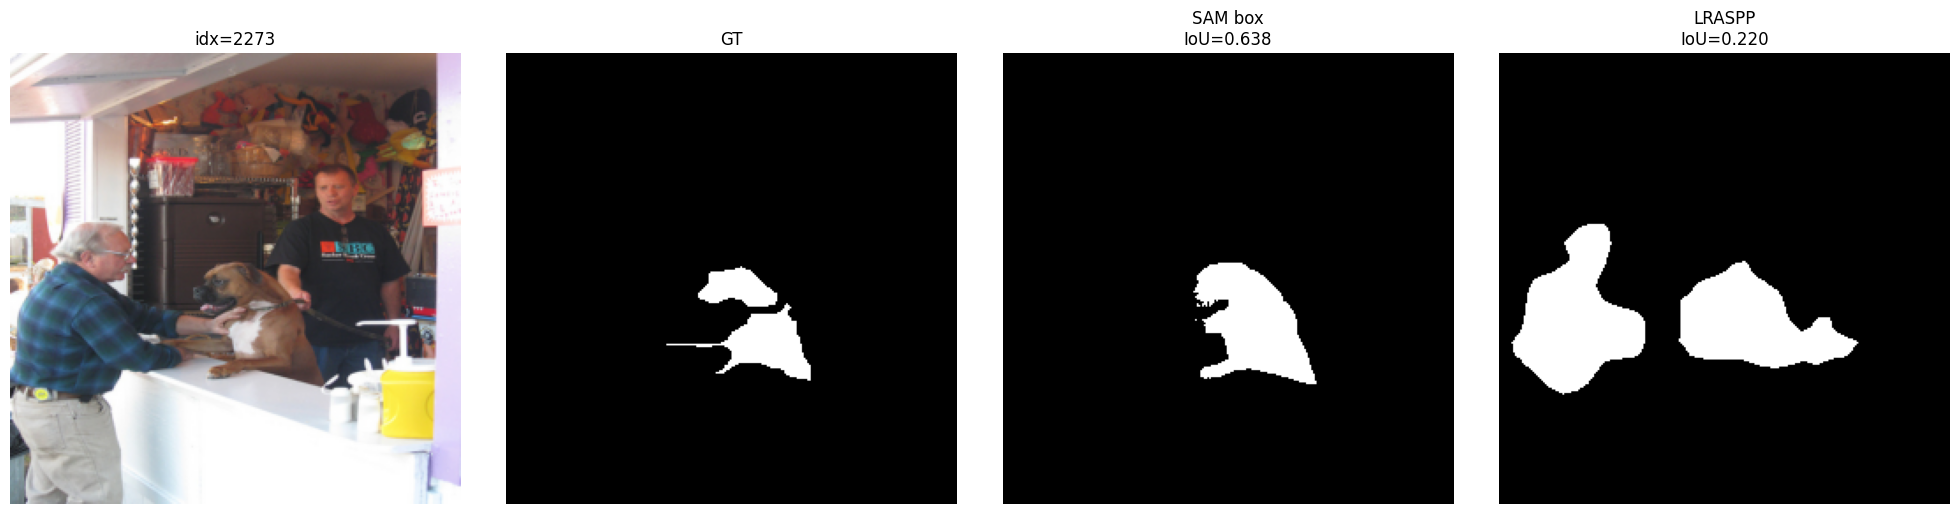


Случай, где LRASPP лучше (разница +0.855):


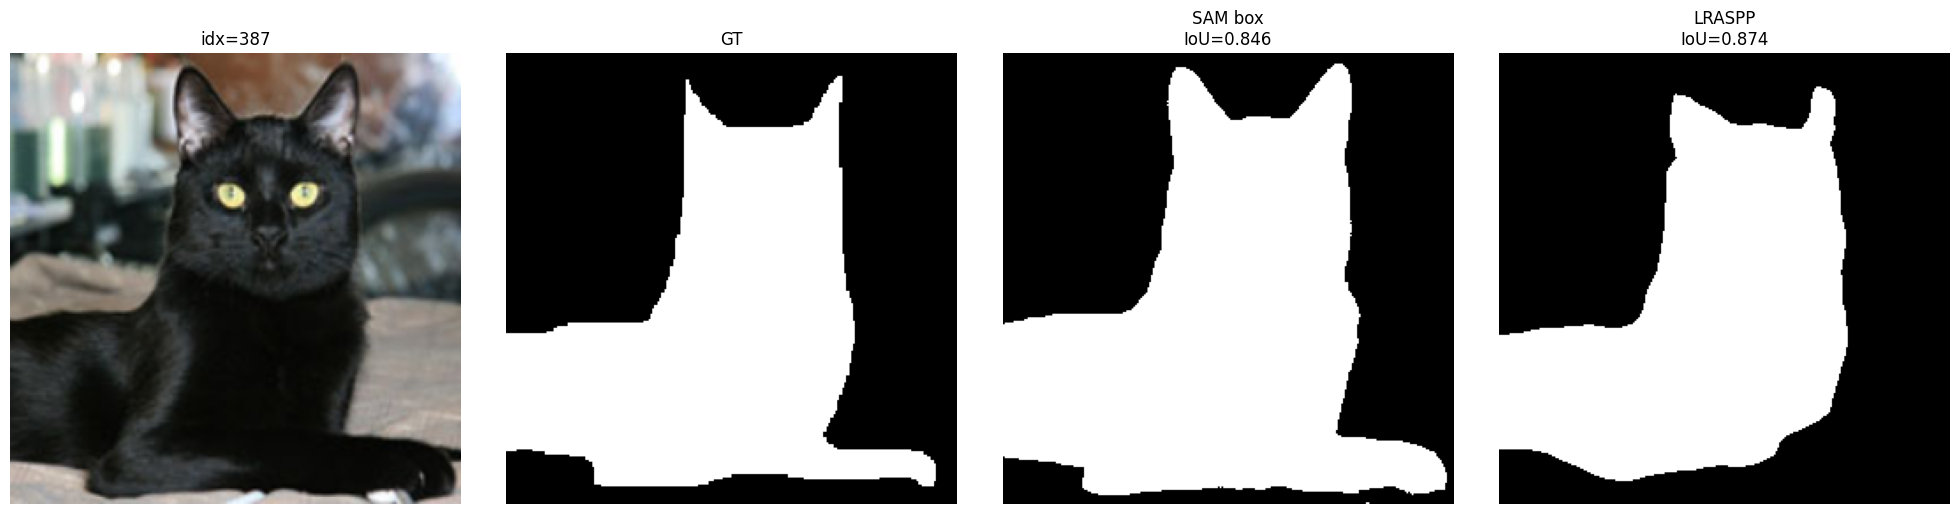

In [ ]:
import matplotlib.pyplot as plt

def show_sam_vs_sup(idx):
    img_t, gt_t = full_ds[idx]
    gt_bin = (gt_t.numpy().squeeze() == 1)
    img_np = img_t.permute(1, 2, 0).numpy()

    # SAM box
    box = box_from_mask(gt_bin)
    m_sam, _ = predict_sam(img_t, processor, model, box=box)

    # LRASPP
    with torch.no_grad():
        out = lraspp(img_t.unsqueeze(0).to(DEVICE))["out"]
        m_sup = (torch.sigmoid(out) > 0.5).squeeze().cpu().numpy()

    sam_iou = iou(m_sam, gt_bin)
    sup_iou = iou(m_sup, gt_bin)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(img_np);         axes[0].set_title(f"idx={idx}")
    axes[1].imshow(gt_bin, cmap="gray"); axes[1].set_title("GT")
    axes[2].imshow(m_sam, cmap="gray");  axes[2].set_title(f"SAM box\nIoU={sam_iou:.3f}")
    axes[3].imshow(m_sup, cmap="gray");  axes[3].set_title(f"LRASPP\nIoU={sup_iou:.3f}")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    plt.show()

# сортировка чтобы найти максимальный разрыв
# SAM лучше всего (SAM - LRASPP) максимальна
best_sam = sorted(supervised_comparison, key=lambda r: r["sam_box_iou"] - r["supervised_iou"], reverse=True)[0]
# LRASPP лучше всего (LRASPP - SAM) максимальна
best_sup = sorted(supervised_comparison, key=lambda r: r["supervised_iou"] - r["sam_box_iou"], reverse=True)[0]

# случай, где SAM значимо лучше
if best_sam["sam_box_iou"] > best_sam["supervised_iou"] + 0.05:
    diff = best_sam["sam_box_iou"] - best_sam["supervised_iou"]
    print(f"\nСлучай, где SAM лучше (разница +{diff:.3f}):")
    show_sam_vs_sup(best_sam["index"])
else:
    print("\nНе найдено случаев, где SAM был бы значимо лучше LRASPP на >0.05 IoU.")

# случай, где LRASPP значимо лучше
if best_sup["supervised_iou"] > best_sup["sam_box_iou"] + 0.05:
    diff = best_sup["supervised_iou"] - best_sup["sam_box_iou"]
    print(f"\nСлучай, где LRASPP лучше (разница +{diff:.3f}):")
    show_sam_vs_sup(best_sup["index"])
else:
    print("\nНе найдено случаев, где LRASPP был бы значимо лучше SAM на >0.05 IoU.")

### Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm

refine_train = []

for idx in tqdm(train_indices, desc="SAM для train (refine)"):
    img_tensor, gt_mask = full_ds[idx]
    gt_bin = (gt_mask.numpy().squeeze() == 1)

    if gt_bin.sum() == 0:
        continue

    # SAM по box-промпту (как самый точный)
    box = box_from_mask(gt_bin)
    sam_mask, _ = predict_sam(img_tensor, processor, model, box=box)

    # отсев мусорных пар если SAM совсем мимо (IoU < 0.05), пропускаем
    if iou(sam_mask, gt_bin) < 0.05:
        continue

    # 4-канальный вход RGB (3) + SAM-маска (1)
    mask_ch = torch.from_numpy(sam_mask.astype(np.float32)).unsqueeze(0)
    input_4ch = torch.cat([img_tensor, mask_ch], dim=0) #(4, H, W)
    target = torch.from_numpy(gt_bin.astype(np.float32)).unsqueeze(0) # (1, H, W)

    refine_train.append({
        "index": int(idx),
        "input": input_4ch,
        "target": target,
        "sam_iou": float(iou(sam_mask, gt_bin)),
    })

torch.save(refine_train, ARTIFACTS / "refine_train.pt")

sam_ious = [d["sam_iou"] for d in refine_train]
print(f"\nСформировано {len(refine_train)} примеров")
print(f"SAM IoU на train: mean={np.mean(sam_ious):.3f}, std={np.std(sam_ious):.3f}")


SAM для train (refine):   0%|          | 0/200 [00:00<?, ?it/s]


Сформировано 199 примеров
SAM IoU на train: mean=0.780, std=0.110


Взяли 200 тренировочных картинок и для каждой получили маску от SAM по рамке (box-промпту). Каждую картинку и ее SAM-маску склеили в единый 4-хканальный (3 канала цвета + 1 канал маски), чтобы нейросеть-корректор училась исправлять ошибки SAM. В итоге собрали 199 обучающих пар, где SAM сам в среднем попадал в питомца с точностью 0.78 значит, данные для обучения корректора готовы.

### Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
import numpy as np
import time

# загрузка данных
refine_train = torch.load(ARTIFACTS / "refine_train.pt")

# датасет и DataLoader
inputs  = torch.stack([d["input"]  for d in refine_train])
targets = torch.stack([d["target"] for d in refine_train])

train_dataset = TensorDataset(inputs, targets)
train_loader  = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)

# корректирующая голова (простая CNN)
class RefinementHead(nn.Module):
    def __init__(self, in_channels=4, mid_channels=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, 3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, mid_channels, 3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, 1, 1),
        )
    def forward(self, x):
        return self.net(x)

refine_head = RefinementHead(in_channels=4).to(DEVICE)

# лосс и оптимизатор
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(refine_head.parameters(), lr=1e-3)

num_epochs = 5 if FAST_DEV_RUN else 10
t0 = time.time()

# обучение
for epoch in range(num_epochs):
    refine_head.train()
    total_loss = 0
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = refine_head(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs}  loss={total_loss/len(train_loader):.4f}")

torch.save(refine_head.state_dict(), ARTIFACTS / "refinement.pt")


Epoch 1/10:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 1/10  loss=0.3096


Epoch 2/10:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 2/10  loss=0.2275


Epoch 3/10:   0%|          | 0/25 [00:00<?, ?it/s]

...

Epoch 8/10  loss=0.1744


Epoch 9/10:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 9/10  loss=0.1768


Epoch 10/10:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 10/10  loss=0.1774


Обучили маленькую нейросеть-корректор, которая получает картинку вместе с маской от SAM и пытается исправить ее ошибки, чтобы она точнее совпадала с настоящей разметкой. Модель училась на 199 примерах и довольно быстро вышла на свой предел, перестав сильно уменьшать ошибку после 5-6 эпох. Итоговая ошибка остановилась на уровне 0.17, что для такой маленькой выборки является хорошим результатом.

### Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import json
from tqdm.auto import tqdm

# архитектура головы
class RefinementHead(nn.Module):
    def __init__(self, in_channels=4, mid_channels=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, 3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, mid_channels, 3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, 1, 1),
        )
    def forward(self, x):
        return self.net(x)

# загрузка обученных весов
refine_head = RefinementHead(in_channels=4).to(DEVICE)
refine_head.load_state_dict(torch.load(ARTIFACTS / "refinement.pt", map_location=DEVICE))
refine_head.eval()

# оценка на eval-изображениях
adapted_comparison = []

with torch.no_grad():
    for idx in tqdm(eval_indices, desc="Correction on eval"):
        img_tensor, gt_mask = full_ds[idx]
        gt_bin = (gt_mask.numpy().squeeze() == 1)
        if gt_bin.sum() == 0:
            continue

        # SAM-маска по box-промпту
        box = box_from_mask(gt_bin)
        sam_mask, _ = predict_sam(img_tensor, processor, model, box=box)

        # 4-канальный вход RGB + SAM-маска
        mask_ch = torch.from_numpy(sam_mask.astype(np.float32)).unsqueeze(0)
        input_4ch = torch.cat([img_tensor, mask_ch], dim=0).unsqueeze(0).to(DEVICE)

        # применение головы
        refined_logits = refine_head(input_4ch)
        refined_mask = (torch.sigmoid(refined_logits) > 0.5).squeeze().cpu().numpy()

        # IoU до и после
        sam_iou     = float(iou(sam_mask, gt_bin))
        refined_iou = float(iou(refined_mask, gt_bin))

        adapted_comparison.append({
            "index": int(idx),
            "sam_iou":     sam_iou,
            "refined_iou": refined_iou,
            "improvement": refined_iou - sam_iou,
            "needs_correction": bool(sam_iou < 0.5),
        })

with open(ARTIFACTS / "adapted_comparison.json", "w") as f:
    json.dump(adapted_comparison, f, indent=2)

sam_ious = [r["sam_iou"]     for r in adapted_comparison]
refined_ious = [r["refined_iou"] for r in adapted_comparison]
improvements = [r["improvement"] for r in adapted_comparison]
needs_corr = [r["needs_correction"] for r in adapted_comparison]

print(f"SAM mean IoU: {np.mean(sam_ious):.4f}")
print(f"Refined mean IoU: {np.mean(refined_ious):.4f}")
print(f"Улучшение: {np.mean(improvements):+.4f}")
print(f"Доля масок < 0.5: {np.mean(needs_corr)*100:.1f}%")

Correction on eval:   0%|          | 0/50 [00:00<?, ?it/s]

SAM mean IoU: 0.7851
Refined mean IoU: 0.8401
Улучшение: +0.0550
Доля масок < 0.5: 4.0%



Случай, где refinement помог:


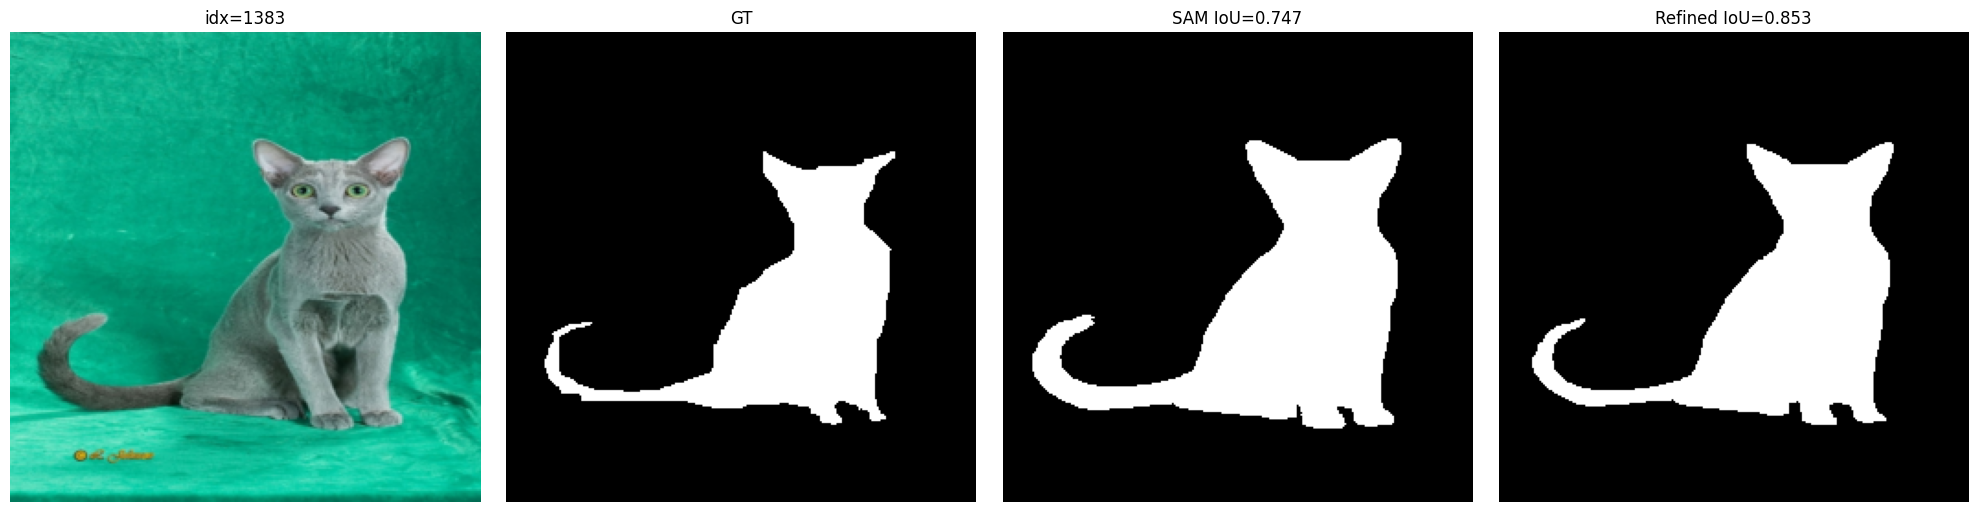

In [ ]:
def show_refinement(idx):
    img_t, gt_t = full_ds[idx]
    gt_bin = (gt_t.numpy().squeeze() == 1)
    img_np = img_t.permute(1, 2, 0).numpy()

    # SAM
    box = box_from_mask(gt_bin)
    m_sam, _ = predict_sam(img_t, processor, model, box=box)

    # Refined
    mask_ch = torch.from_numpy(m_sam.astype(np.float32)).unsqueeze(0)
    x = torch.cat([img_t, mask_ch], dim=0).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        m_ref = (torch.sigmoid(refine_head(x)) > 0.5).squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(img_np);             axes[0].set_title(f"idx={idx}")
    axes[1].imshow(gt_bin, cmap="gray"); axes[1].set_title("GT")
    axes[2].imshow(m_sam, cmap="gray");  axes[2].set_title(f"SAM IoU={iou(m_sam, gt_bin):.3f}")
    axes[3].imshow(m_ref, cmap="gray");  axes[3].set_title(f"Refined IoU={iou(m_ref, gt_bin):.3f}")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    plt.show()


# где голова помогла и где навредила
helped = [r for r in adapted_comparison if r["improvement"] > 0.1]
hurt   = [r for r in adapted_comparison if r["improvement"] < -0.1]


if helped:
    print("\nСлучай, где refinement помог:")
    show_refinement(helped[0]["index"])

if hurt:
    print("\nСлучай, где refinement навредил:")
    show_refinement(hurt[0]["index"])

### Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import json
import numpy as np

# сбор IoU
sam_by_idx = {r["index"]: r["box"]["iou"] for r in prompt_results}
sup_by_idx = {r["index"]: r["supervised_iou"] for r in supervised_comparison}
ref_by_idx = {r["index"]: r["refined_iou"] for r in adapted_comparison}

common_idx = sorted(set(sam_by_idx) & set(sup_by_idx) & set(ref_by_idx))

# случаи деградации
correction_failures = []
for idx in common_idx:
    sam_i = sam_by_idx[idx]
    ref_i = ref_by_idx[idx]
    if ref_i < sam_i:
        correction_failures.append({
            "index": int(idx),
            "sam_iou": float(sam_i),
            "supervised_iou": float(sup_by_idx[idx]),
            "refined_iou": float(ref_i),
        })

# сортировка по деградации
correction_failures.sort(key=lambda r: -(r["sam_iou"] - r["refined_iou"]))

with open(ARTIFACTS / "correction_failures.json", "w") as f:
    json.dump(correction_failures, f, indent=2)

# метрики
print(f"Всего: {len(common_idx)}")
print(f"Случаев деградации: {len(correction_failures)} "f"({len(correction_failures)/len(common_idx)*100:.1f}%)")

Всего: 50
Случаев деградации: 13 (26.0%)


Проверили, как обученная модель-корректор справляется с масками SAM на новых тестовых картинках и сравнили результаты. В среднем корректор улучшил качество масок с 0.78 до 0.84 IoU, но при этом в 26% случаев (13 из 50 картинок) он случайно испортил маску, которая изначально была хорошей.

### Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.

Мы сравнили 3 подхода на 50 тестовых картинках. SAM без обучения дал точность 0.77, наша обученная с нуля модель 0.80, а связка SAM с обученным корректором лучший результат 0.84. Предобученная SAM почти не уступает специализированной модели даже без дообучения, а добавление маленькой обучаемой головы позволяет обогнать ее. Основные ограничения маленькая выборка (50 тестовых и 200 обучающих картинок) и облегченная версия модели из-за нехватки ресурсов, поэтому корректор иногда (в 26% случаев) портит уже хорошие маски.